In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import minimize

from jax import random
from numpyro import distributions as dist

from tqdm.auto import tqdm

from utils.plots import *
from utils.signal import *

param_dir = Path('../../prior_params')


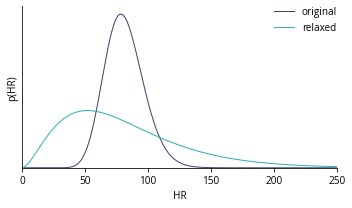

In [3]:
alpha_hr = np.load(param_dir / 'alpha_hr.npy').item()
lambd_hr = np.load(param_dir / 'lambd_hr.npy').item()

x = np.linspace(0, 250, 1000)
y = np.exp(dist.Gamma(alpha_hr, lambd_hr).log_prob(x))

plt.figure(figsize=(5,3))
plt.plot(x, y, label='original')

alpha_hr *= 0.1
lambd_hr *= 0.1
y = np.exp(dist.Gamma(alpha_hr, lambd_hr).log_prob(x))
plt.plot(x, y, label='relaxed', c=cp[3])

# alpha_hr *= 0.01
# lambd_hr *= 0.01
# y = np.exp(dist.Gamma(alpha_hr, lambd_hr).log_prob(x))
# plt.plot(x, y, label='ablated', c=cp[1])

plt.legend(loc='upper right', frameon=False, borderpad=0, borderaxespad=0)
plt.xlabel('HR')
plt.ylabel('p(HR)')
plt.yticks([])
plt.ylim(0, None)
plt.show()


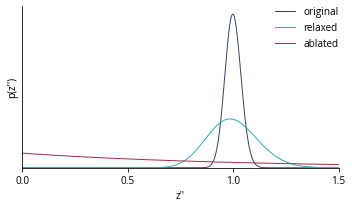

In [4]:
alpha_zpp = np.load(param_dir / 'alpha_zpp.npy').item()

x = np.linspace(0, 1.5, 1000)
y = np.exp(dist.Gamma(alpha_zpp, alpha_zpp).log_prob(x))

plt.figure(figsize=(5,3))
plt.plot(x, y, label='original')

alpha_zpp *= 0.1
y = np.exp(dist.Gamma(alpha_zpp, alpha_zpp).log_prob(x))
plt.plot(x, y, label='relaxed', c=cp[3])

# alpha_zpp *= 0.03
alpha_zpp = 1
y = np.exp(dist.Gamma(alpha_zpp, alpha_zpp).log_prob(x))
plt.plot(x, y, label='ablated', c=cp[1])


plt.xticks([0, 0.5, 1, 1.5])
plt.legend(loc='upper right', frameon=False, borderpad=0, borderaxespad=0)
plt.xlabel("z''")
plt.ylabel("p(z'')")
plt.yticks([])
plt.ylim(0, None)
plt.show()


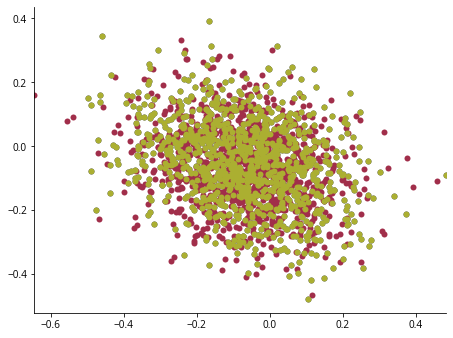

In [ ]:
from numpyro import distributions as dist

mu_w = np.load(param_dir / 'mu_w.npy')
L_w = np.load(param_dir / 'L_w.npy')


N = 1000

mvn_1 = dist.MultivariateNormal(0, np.eye(mu_w.size))
samples_1 = mvn_1.sample(random.key(0), (N,))
samples_1 = mu_w + samples_1 @ L_w

Sigma_w = L_w @ L_w.T
mvn_2 = dist.MultivariateNormal(mu_w, Sigma_w)
samples_2 = mvn_2.sample(random.key(0), (N,))

# plt.scatter(samples_1[:,4], samples_1[:,5], lw=0)
plt.scatter(samples_2[:,4], samples_2[:,5], lw=0)

mvn_3 = dist.MultivariateNormal(0, np.eye(2))
samples_3 = mvn_3.sample(random.key(0), (N,))
samples_3 = mu_w[4:6] + samples_3 @ L_w[4:6,4:6]

Sigma_w = L_w @ L_w.T
mvn_4 = dist.MultivariateNormal(mu_w[4:6], Sigma_w[4:6,4:6])
samples_4 = mvn_4.sample(random.key(0), (N,))

Sigma_w = L_w @ L_w.T
mvn_5 = dist.MultivariateNormal(mu_w, Sigma_w)
samples_5 = mvn_5.sample(random.key(0), (N,))
samples_5 = samples_5[:,4:6]

# plt.scatter(samples_2[:,4], samples_2[:,5], lw=0)
# plt.scatter(samples_3[:,0], samples_3[:,1], lw=0)
plt.scatter(samples_4[:,0], samples_4[:,1], lw=0)
plt.scatter(samples_5[:,0], samples_5[:,1], lw=0)
plt.show()



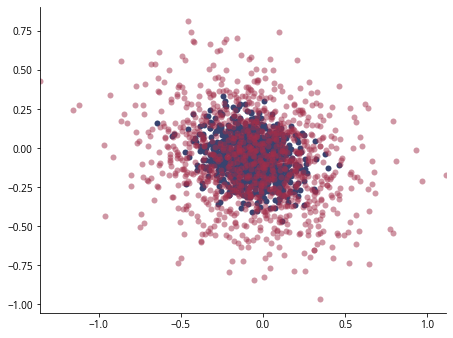

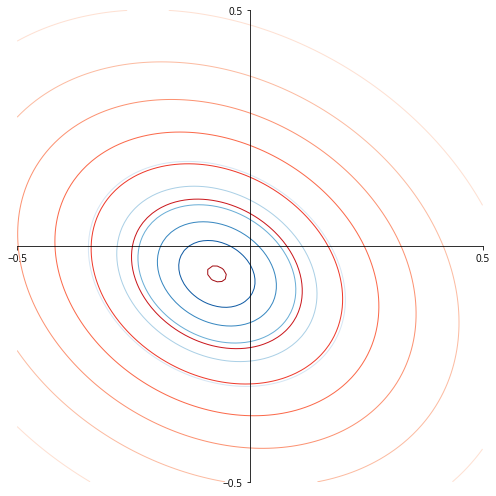

In [29]:
N = 1000

mu_w = np.load(param_dir / 'mu_w.npy')
L_w = np.load(param_dir / 'L_w.npy')

Sigma_w = L_w @ L_w.T

mvn_1 = dist.MultivariateNormal(mu_w[4:6], Sigma_w[4:6,4:6])
samples_1 = mvn_1.sample(random.key(0), (N,))

Sigma_w @= np.eye(mu_w.size) * 5.0

mvn_2 = dist.MultivariateNormal(mu_w[4:6], Sigma_w[4:6,4:6])
samples_2 = mvn_2.sample(random.key(0), (N,))

# plt.scatter(samples_2[:,4], samples_2[:,5], lw=0)
# plt.scatter(samples_3[:,0], samples_2[:,1], lw=0)
plt.scatter(samples_1[:,0], samples_1[:,1], lw=0)
plt.scatter(samples_2[:,0], samples_2[:,1], lw=0, alpha=0.5)
plt.show()


xmin, xmax, ymin, ymax = -0.5, 0.5, -0.5, 0.5
x_grid, y_grid = np.meshgrid(np.linspace(xmin, xmax, 101), np.linspace(ymin, ymax, 101))
pos = np.dstack((x_grid, y_grid))

pdf_1 = np.exp(mvn_1.log_prob(pos)) # / np.exp(mvn_1.log_prob(mu_w[4:6]))
pdf_2 = np.exp(mvn_2.log_prob(pos)) # / np.exp(mvn_2.log_prob(mu_w[4:6]))

plt.figure(figsize=(7,7))
# plt.contour(x_grid, y_grid, pdf_1, levels=[0.25, 0.5, 0.75], cmap='Blues')
# plt.contour(x_grid, y_grid, pdf_2, levels=[0.25, 0.5, 0.75], cmap='Reds')
plt.contour(x_grid, y_grid, pdf_1, cmap='Blues')
plt.contour(x_grid, y_grid, pdf_2, cmap='Reds')

plt.gca().spines['left'].set_position('zero')
plt.gca().spines['bottom'].set_position('zero')
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)
plt.xticks([xmin, xmax])
plt.yticks([ymin, ymax])

plt.show()


In [33]:
L = np.linalg.cholesky(np.eye(2)*0.5+0.5)
L = np.linalg.cholesky(np.eye(3))
L

# L_w @ L_w.T



array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])